# 18) Some More Python #

Today we will talk about a few more Python libraries and tricks. In particular, we will talk about the Math, matplotlib, and time libraries. Starting next class, we will talk about the PULP solver.

In [11]:
import math
#This is the standard way to import the plotting library in python. Similar to how numpy is usually np
import matplotlib.pyplot as plt
import time

In [12]:
#The math library has most math operations. In particular, you may find the factorial and trig functions helpful

#The library also has stored constants
print(math.cos(2*math.pi))

print(math.factorial(4))

1.0
24


## While Loops ##

A while loop in Python will repeatedly run a block of code until some condition is satisfied.

In [13]:
#We want to find the largest n such that n! is less than 10^7.

#Initialize the factorial
fact = 1
#This is the counter
i= 1

#The while loop will run the code until a sufficiently large factorial is found
while fact < 10**7:
    fact *= i
    i += 1

#This is the first one that is larger than 10^7
print(fact/(i-1))
#Here is the corresponding index
print(i-2)

3628800.0
10


In [14]:
#We can compare this value to the math factorial function for reference.
math.factorial(10)

3628800

## Functions ##

If you want to run similar lines of code with slightly different inputs, you can use a function. These are similar to functions in math. Suppose we wish to create the function $y=7x+3$. There are two ways of doing this in Python. First is a standard function.

In [15]:
def linear_y(x):
  #Everything in  the triple quotes is a docstring. This will appear if you call help on the function.

  '''
  This function takes a float, x and outputs y=7x+3.

  Inputs:
    x (float)

  Outputs:
    y (float)
  '''

  y = 7*x+3

  return y

print(linear_y(5))
print(help(linear_y))

38
Help on function linear_y in module __main__:

linear_y(x)
    This function takes a float, x and outputs y=7x+3.

    Inputs:
      x (float)

    Outputs:
      y (float)

None


For smaller functions, you can also store the function as a variable using lambda functions. Both work in Python.

In [16]:
#Lambda Functions

#We are calling this function y
y = lambda x: 7*x + 3

print(y(5))

#If we make a list of x values here
xs = [1,653,2134234,5675675,234234,74,2123,452342672]
#We can use the syntax below to create a list of y values. This is called list comprehension.
ys = [y(x) for x in xs]
print(ys)

38
[10, 4574, 14939641, 39729728, 1639641, 521, 14864, 3166398707]


In [17]:
#Suppose we want f(x,y) = x*y. This has two inputs.
f = lambda x, y: x*y

print(f(65,2))

130


In [18]:
#The time library can measure the time since a fixed reference.
#Taking the difference of two times can tell us how long code takes to run.

#Let's check how long this block of code takes!
t0 = time.time()

for k in range(1000):
  xs = [1235123*i - 1235123*i**2 for i in range(100)]
  ys = [y(x) for x in xs]

t1 = time.time()

print(t1 - t0)

0.0642857551574707


## Matplotlib ##

This is one of the oldest libraries in Python. It has some quirks, but is useful for making plots quickly.

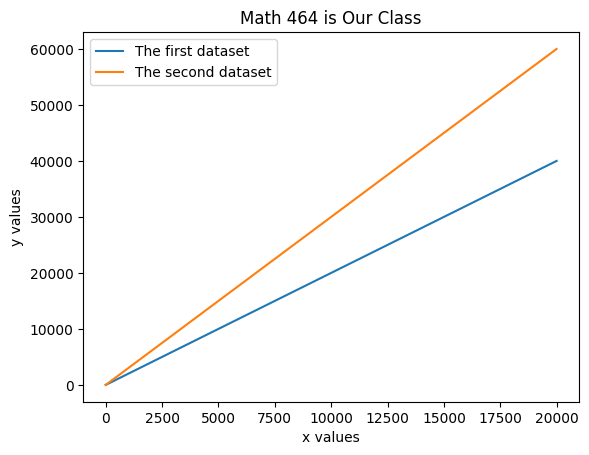

In [21]:
#This is a list of x values
xs = [i for i in range(2*10**4)]
#This is a list of y values
ys = [2*i-4 for i in xs]

#We add the first line from the x,y values
plt.plot(xs, ys, label="The first dataset")

#We can add a second line to the plot
ws = [3*i-4 for i in xs]
plt.plot(xs, ws, label = "The second dataset")

#This adds a title to the plot and labels the axis
plt.title("Math 464 is Our Class")
plt.xlabel("x values")
plt.ylabel("y values")

#This creates a legend in the plot
plt.legend()
#Use show and close to help prevent memory leak
plt.show()
plt.close()

# Practice Problems #

1) Implement the factorial function in Python. Compare the runtimes of your function to "math.factorial".

2) Create a plot of the runtimes for $n=1$ to $n=1000$.

3) Find the first Fibbonacci number greater than $10,000,000$.

4) Plot all the Fibonacci numbers less than $10,000,000$ on the y-axis with the index on the x-axis.

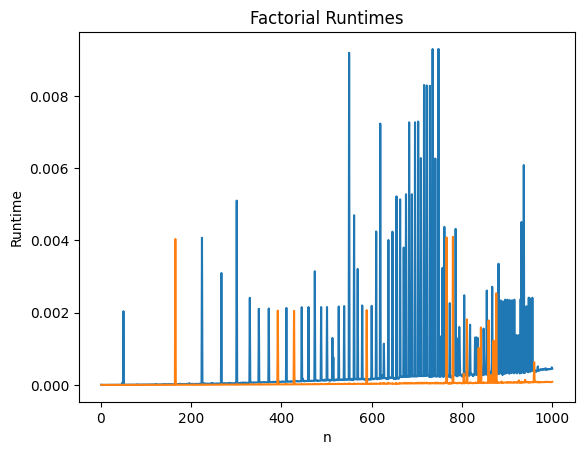

14930352


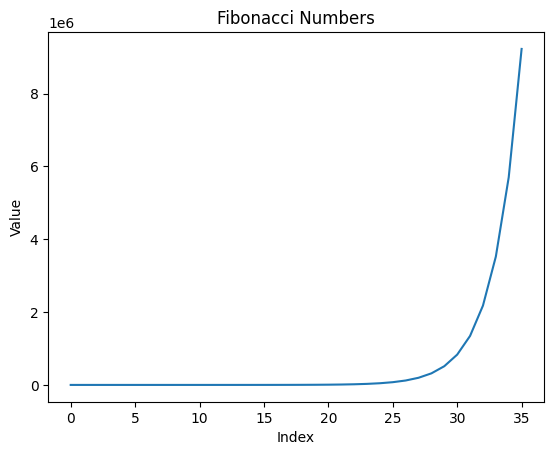

In [26]:
#1

def fact(n):
  '''Computes n!

  inputs:
    n: A Positive integer

  outputs:
    f: n!
  '''

  f = 1

  for i in range(1,n+1):
    f *= i

  return f

r0 = []
r1 = []
r2 = []
r3 = []

for i in range(1,1001):
  r0.append(time.time())

  a = fact(i)

  r1.append(time.time())

  r2.append(time.time())

  a = math.factorial(i)

  r3.append(time.time())

times0 = [r1[i] - r0[i] for i in range(len(r0))]
times1 = [r3[i] - r2[i] for i in range(len(r1))]

plt.plot(range(1,1001), times0)
plt.plot(range(1,1001), times1)
plt.title("Factorial Runtimes")
plt.xlabel("n")
plt.ylabel("Runtime")
plt.show()
plt.close()

#3
fibs = [0,1]
current_fib = 1

while current_fib < 10**7:
  current_fib = fibs[-1] + fibs[-2]
  fibs.append(current_fib)

print(fibs[-1])

#4
xs = [i for i in range(len(fibs)-1)]
plt.plot(xs, fibs[:-1])
plt.title("Fibonacci Numbers")
plt.xlabel("Index")
plt.ylabel("Value")
plt.show()
plt.close()